# A2 – Study, Implement and Present a Machine Learning Model
## Value-aware neural network for telecom churn retention (NumPy from scratch)

**Option 1 + 2 hybrid.** A fully-connected neural network (forward pass, back-propagation, Adam, L2, early stopping, gradient check) is implemented **from scratch in NumPy** (no deep-learning library) and applied to a **real, non-trivial dataset** (IBM Telco Customer Churn, 7,043 customers, 19 raw features).

**Research question.** A churn model is trained with cross-entropy, but the business objective is *retention profit*: contacting a churner with a retention offer is worth very different amounts for different customers. *Does replacing the cross-entropy loss with a loss derived from the decision-theoretic profit matrix (value-weighted cross-entropy) increase realised profit on unseen customers, and what does it cost in calibration?*

**Notebook map** (every section is self-contained and re-runnable top-to-bottom; ~10 min on Colab CPU):
1. Setup & data download → 2. Task definition (I/O) & business model → 3. Pre-processing → 4. MLP from scratch + gradient check → 5. Training procedure → 6. Baselines → 7. Repeated-split experiment → 8. Results/statistics → 9. Behaviour analysis (confusion, calibration, value capture) → 10. Loss-vs-objective mismatch → 11. Sensitivity to business assumptions → 12. Generalisation-gap study → 13. Export numbers for the report.

## 1. Setup and data download

In [1]:
import os, json, time, warnings, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

SEED      = 2025
N_SPLITS  = 10      # repeated stratified 60/20/20 splits (train / validation / test)
FAST      = False   # set True for a ~2 min smoke-test (3 splits)
if FAST: N_SPLITS = 3
os.makedirs("figs", exist_ok=True)

URL  = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
PATH = "Telco-Customer-Churn.csv"
if not os.path.exists(PATH):
    urllib.request.urlretrieve(URL, PATH)       # data download is part of the notebook (self-contained)
raw = pd.read_csv(PATH)
print(raw.shape); raw.head(3).T

(7043, 21)


,0,1,2
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK
gender,Female,Male,Male
SeniorCitizen,0,0,0
Partner,Yes,No,No
Dependents,No,No,No
tenure,1,34,2
PhoneService,No,Yes,Yes
MultipleLines,No phone service,No,No
InternetService,DSL,DSL,DSL
OnlineSecurity,No,Yes,Yes


In [2]:
df = raw.copy()
# TotalCharges is stored as text; 11 blank rows are customers with tenure == 0 (no bill issued yet) -> 0 is the correct value
print("blank TotalCharges:", (df.TotalCharges.str.strip()=="").sum(), "| tenure==0 rows:", (df.tenure==0).sum())
df["TotalCharges"] = pd.to_numeric(df.TotalCharges.str.strip().replace("", np.nan)).fillna(0.0)
df["y"] = (df.Churn=="Yes").astype(int)
FEATS_NUM = ["tenure","MonthlyCharges","TotalCharges"]
FEATS_CAT = [c for c in df.columns if c not in FEATS_NUM+["customerID","Churn","y"]]
print("numeric:", FEATS_NUM); print("categorical:", FEATS_CAT)
print(f"churn rate = {df.y.mean():.3f}  (class imbalance 1 : {(1-df.y.mean())/df.y.mean():.2f})")
print("duplicates in customerID:", df.customerID.duplicated().sum())

blank TotalCharges: 11 | tenure==0 rows: 11
numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
churn rate = 0.265  (class imbalance 1 : 2.77)
duplicates in customerID: 0


## 2. Task definition and business model

**Input (training and deployment)** – one customer record $x$ of 19 raw fields: 3 numeric (`tenure` in months 0–72, `MonthlyCharges` ≈ \$18–119, `TotalCharges` ≥ 0) and 16 categorical (contract type, internet service, payment method, …). After pre-processing: a real vector $x\in\mathbb{R}^{d}$ ($d=46$): 3 z-scored numerics + one-hot encodings whose levels are learned on the training split only.

**Training label** – $y\in\{0,1\}$, $y=1$ iff the customer left in the following month (observed, 26.5 % positive).

**Model output** – a real logit $z=f_\theta(x)$; $\sigma(z)=1/(1+e^{-z})$ is the model's probability of churn. **Deployment output** – a binary action $a\in\{0,1\}$: send the retention offer or not.

**Decision-theoretic objective.** An offer costs $c$ (a discount, default \$100). If the customer would churn, the offer saves them with probability $s$ (default 0.4) and the saved revenue is $V=H\cdot$`MonthlyCharges` ($H=12$ months). Utility matrix:

| | churner ($y=1$) | stayer ($y=0$) |
|---|---|---|
| contact | $sV-c$ | $-c$ |
| do not contact | 0 | 0 |

Contact is optimal iff $p\,sV>c$, i.e. **$p>c/(sV)$ – a per-customer threshold**. A global 0.5 threshold or an accuracy/AUC objective ignores this. We therefore report *profit per customer* and the *share of the oracle profit captured* (oracle = contact exactly the churners with $sV>c$).

*Assumptions are stated, not hidden*: $s$, $c$, $H$ are business inputs (not in the data); Section 11 sweeps them. The label is observational churn, not uplift – see Discussion in the report.

In [3]:
H, S_SUCCESS, C_OFFER = 12, 0.40, 100.0          # horizon (months), offer success prob., offer cost ($)

def sV_of(df_, s=S_SUCCESS, H=H):  return s * H * df_["MonthlyCharges"].values   # expected saved revenue if contacted churner is saved

def profit_per_customer(contact, y, sV, c=C_OFFER):
    # realised profit per customer: contacted churner -> sV - c ; contacted stayer -> -c ; not contacted -> 0
    return float(np.mean(contact * (y * sV - c)))

def oracle_profit(y, sV, c=C_OFFER):
    return profit_per_customer(((y == 1) & (sV > c)).astype(float), y, sV, c)

sv = sV_of(df)
print(f"mean sV = ${sv.mean():.0f};  customers with sV<=c (never worth contacting): {(sv<=C_OFFER).mean():.1%}")
print(f"profit/customer  contact-all: {profit_per_customer(np.ones(len(df)), df.y.values, sv):.2f} | contact-none: 0 | oracle: {oracle_profit(df.y.values, sv):.2f}")

mean sV = $311;  customers with sV<=c (never worth contacting): 16.0%
profit/customer  contact-all: -5.18 | contact-none: 0 | oracle: 68.35


## 3. Pre-processing (fitted on the training split only → no leakage)

In [4]:
class Preprocessor:
    # z-score numerics, one-hot categoricals; statistics/levels come from the TRAIN split only.
    def fit(self, d):
        self.mu = d[FEATS_NUM].mean().values; self.sd = d[FEATS_NUM].std().values + 1e-8
        self.levels = {c: sorted(d[c].unique()) for c in FEATS_CAT}
        self.names = FEATS_NUM + [f"{c}={l}" for c in FEATS_CAT for l in self.levels[c]]
        return self
    def transform(self, d):
        num = (d[FEATS_NUM].values - self.mu) / self.sd
        cat = [(d[c].to_numpy(dtype=object)[:, None] == np.array(self.levels[c], dtype=object)[None, :]).astype(float) for c in FEATS_CAT]
        return np.hstack([num] + cat)

def make_split(seed):
    # stratified 60/20/20 split by label
    rng = np.random.RandomState(seed); tr, va, te = [], [], []
    for lab in (0, 1):
        idx = rng.permutation(np.where(df.y.values == lab)[0]); n = len(idx)
        tr += list(idx[:int(.6*n)]); va += list(idx[int(.6*n):int(.8*n)]); te += list(idx[int(.8*n):])
    return np.array(tr), np.array(va), np.array(te)

tr, va, te = make_split(0)
pp = Preprocessor().fit(df.iloc[tr]); Xtmp = pp.transform(df.iloc[tr])
print("split sizes:", len(tr), len(va), len(te), "| feature dim d =", Xtmp.shape[1])
print("train mean (num) ~0:", Xtmp[:, :3].mean(0).round(3), " std ~1:", Xtmp[:, :3].std(0).round(3))

split sizes: 4225 1409 1409 | feature dim d = 46
train mean (num) ~0: [ 0.  0. -0.]  std ~1: [1. 1. 1.]


## 4. The model: an MLP implemented from scratch

For input $x$, a network with two hidden layers of width $h$:
$$a_0=x,\quad z_\ell=a_{\ell-1}W_\ell+b_\ell,\quad a_\ell=\mathrm{ReLU}(z_\ell)\ (\ell=1,2),\quad z=a_2W_3+b_3,\quad p=\sigma(z).$$

**Loss (profit-aware weighted cross-entropy).** With per-sample weights $a_i$ on positives and $b_i$ on negatives
$$\mathcal L(\theta)=\frac1N\sum_i\Big[a_i\,y_i\,\mathrm{softplus}(-z_i)+b_i\,(1-y_i)\,\mathrm{softplus}(z_i)\Big]+\frac{\lambda}{2}\sum_\ell\lVert W_\ell\rVert_F^2 .$$
Plain cross-entropy is $a_i=b_i=1$. **Derivation of the profit weights.** Regret of not contacting a churner is $sV_i-c$; regret of contacting a stayer is $c$. Hence $a_i=\max(sV_i-c,0)$, $b_i=c$. The weighted-risk minimiser satisfies $q_i=\dfrac{a_ip_i}{a_ip_i+b_i(1-p_i)}$, so the *weighted* posterior exceeds ½ iff $p_i>\dfrac{b_i}{a_i+b_i}=\dfrac{c}{sV_i}$ — exactly the Bayes-optimal contact rule. The decision rule for the weighted model is therefore simply "contact iff $z_i>0$" – the per-customer threshold is baked into the weights.

**Back-propagation.** With $\partial\mathcal L/\partial z_i=\tfrac1N\big[b_i(1-y_i)\,p_i-a_iy_i(1-p_i)\big]$, $\;\delta_3=\partial\mathcal L/\partial z$, then $\partial\mathcal L/\partial W_\ell=a_{\ell-1}^\top\delta_\ell+\lambda W_\ell$, $\;\delta_{\ell-1}=(\delta_\ell W_\ell^\top)\odot\mathbb 1[z_{\ell-1}>0]$.

**Optimiser (Adam, from scratch):** $m\leftarrow\beta_1m+(1-\beta_1)g$, $v\leftarrow\beta_2v+(1-\beta_2)g^2$, $\theta\leftarrow\theta-\eta\,\hat m/(\sqrt{\hat v}+\epsilon)$ with bias-corrected $\hat m=m/(1-\beta_1^t)$, $\hat v=v/(1-\beta_2^t)$. Initialisation: He normal $\mathcal N(0,2/\text{fan}_{in})$, matched to ReLU.

In [5]:
def softplus(z):  return np.maximum(z, 0) + np.log1p(np.exp(-np.abs(z)))      # numerically stable log(1+e^z)
def sigmoid(z):   return np.where(z >= 0, 1/(1+np.exp(-np.abs(z))), np.exp(-np.abs(z))/(1+np.exp(-np.abs(z))))

def weighted_bce_from_logits(z, y, a, b):
    # per-sample loss: a*y*softplus(-z) + b*(1-y)*softplus(z)      [= -a y log p - b (1-y) log(1-p)]
    return a * y * softplus(-z) + b * (1 - y) * softplus(z)

class MLP:
    def __init__(self, d, h, seed):
        rng = np.random.RandomState(seed); sizes = [d, h, h, 1]
        self.W = [rng.randn(i, o) * np.sqrt(2.0 / i) for i, o in zip(sizes[:-1], sizes[1:])]     # He init
        self.b = [np.zeros(o) for o in sizes[1:]]
    def forward(self, X, cache=False):
        zs, acts = [], [X]; a = X
        for l in range(3):
            z = a @ self.W[l] + self.b[l]; zs.append(z)
            a = np.maximum(z, 0) if l < 2 else z                                  # ReLU on hidden layers, identity on logit
            acts.append(a)
        return (a[:, 0], zs, acts) if cache else a[:, 0]
    def loss_and_grads(self, X, y, a_w, b_w, l2):
        N = len(y); z, zs, acts = self.forward(X, cache=True); p = sigmoid(z)
        loss = weighted_bce_from_logits(z, y, a_w, b_w).mean() + 0.5 * l2 * sum((W**2).sum() for W in self.W)
        delta = (b_w * (1 - y) * p - a_w * y * (1 - p))[:, None] / N              # dL/dz at the output
        gW, gb = [None]*3, [None]*3
        for l in (2, 1, 0):
            gW[l] = acts[l].T @ delta + l2 * self.W[l]; gb[l] = delta.sum(0)
            if l > 0: delta = (delta @ self.W[l].T) * (zs[l-1] > 0)                # back through ReLU
        return loss, gW, gb
    def params(self):  return self.W + self.b
    def copy_params(self): return [p.copy() for p in self.params()]
    def set_params(self, ps): self.W, self.b = [p.copy() for p in ps[:3]], [p.copy() for p in ps[3:]]

class Adam:
    def __init__(self, params, lr=1e-3, b1=.9, b2=.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t = lr, b1, b2, eps, 0
        self.m = [np.zeros_like(p) for p in params]; self.v = [np.zeros_like(p) for p in params]
    def step(self, params, grads):
        self.t += 1
        for i, (p, g) in enumerate(zip(params, grads)):
            self.m[i] = self.b1*self.m[i] + (1-self.b1)*g
            self.v[i] = self.b2*self.v[i] + (1-self.b2)*g*g
            mh = self.m[i]/(1-self.b1**self.t); vh = self.v[i]/(1-self.b2**self.t)
            p -= self.lr * mh / (np.sqrt(vh) + self.eps)                           # in-place update of the parameter array

### Gradient check – verifies the back-propagation against central finite differences (theory ↔ code)

In [6]:
rng = np.random.RandomState(0)
Xg = rng.randn(40, 7); yg = rng.randint(0, 2, 40).astype(float); ag = rng.rand(40)*3; bg = rng.rand(40)*3
net = MLP(7, 5, seed=1); _, gW, gb = net.loss_and_grads(Xg, yg, ag, bg, l2=0.01)
analytic = [g for g in gW + gb]; max_rel = 0.0
for P, G in zip(net.W + net.b, analytic):
    for _ in range(12):                                                            # 12 random coordinates per tensor
        idx = tuple(rng.randint(s) for s in P.shape); old = P[idx]; e = 1e-6
        P[idx] = old + e; lp = net.loss_and_grads(Xg, yg, ag, bg, 0.01)[0]
        P[idx] = old - e; lm = net.loss_and_grads(Xg, yg, ag, bg, 0.01)[0]; P[idx] = old
        num = (lp - lm)/(2*e); max_rel = max(max_rel, abs(num - G[idx])/max(1e-8, abs(num) + abs(G[idx])))
print(f"max relative error analytic vs numeric gradient: {max_rel:.2e}  ->", "PASS" if max_rel < 1e-5 else "FAIL")
assert max_rel < 1e-5

max relative error analytic vs numeric gradient: 5.02e-07  -> PASS


## 5. Training procedure
Mini-batch Adam (batch 128, lr $10^{-3}$, max 150 epochs), L2 weight decay, **early stopping** on the *validation value of the same objective the model is trained on* (patience 15, best weights restored). Hyper-parameter grid (selected on validation, never on test): width $h\in\{16,64\}$ × $\lambda\in\{10^{-3},10^{-2}\}$.
Per-sample weights are divided by the mean weight on the training set so that the effective learning rate is comparable between the plain and the value-weighted loss (this does not change the minimiser).

In [7]:
def class_weights(df_, mode, c=C_OFFER, s=S_SUCCESS):
    n = len(df_)
    if mode == "bce":   return np.ones(n), np.ones(n)
    sv_ = sV_of(df_, s); return np.maximum(sv_ - c, 0.0), np.full(n, c)           # a_i = max(sV_i - c, 0), b_i = c

def objective_value(z, y, a, b, scale):  return float(np.mean(weighted_bce_from_logits(z, y, a, b)) / scale)

def train_mlp(Xtr, ytr, atr, btr, Xva, yva, ava, bva, h, l2, seed, lr=1e-3, epochs=150, patience=15, batch=128):
    # scale: mean weight of the true class on train, so weighted/unweighted losses have comparable magnitude
    scale = np.mean(np.where(ytr == 1, atr, btr)); atr_, btr_ = atr/scale, btr/scale
    net = MLP(Xtr.shape[1], h, seed); opt = Adam(net.params(), lr); rng = np.random.RandomState(seed)
    best, best_ep, hist = np.inf, 0, {"train": [], "val": []}; best_params = net.copy_params()
    for ep in range(epochs):
        perm = rng.permutation(len(ytr))
        for i in range(0, len(perm), batch):
            j = perm[i:i+batch]
            _, gW, gb = net.loss_and_grads(Xtr[j], ytr[j], atr_[j], btr_[j], l2)
            opt.step(net.params(), gW + gb)
        trl = objective_value(net.forward(Xtr), ytr, atr, btr, scale); val = objective_value(net.forward(Xva), yva, ava, bva, scale)
        hist["train"].append(trl); hist["val"].append(val)
        if val < best - 1e-5: best, best_ep, best_params = val, ep, net.copy_params()
        elif ep - best_ep >= patience: break
    net.set_params(best_params); net.hist, net.best_ep, net.best_val = hist, best_ep, best
    return net

## 6. Baselines and decision rules
* **Contact-all / contact-none / oracle** – reference points for the profit metric.
* **Logistic regression** (scikit-learn; plain and value-weighted via `sample_weight`) – a convex, linear model: tests whether any gain comes from the *loss* rather than from the network.
* **Histogram gradient boosting** (scikit-learn) – a strong tabular benchmark.
* **MLP-BCE + Bayes rule** (contact iff $p_i\,sV_i>c$), **MLP-BCE + tuned global threshold** (threshold chosen to maximise *validation* profit), **MLP-ProfitWBCE** (contact iff $z_i>0$ and $sV_i>c$).

In [8]:
def decision_bayes(z, sv_, c=C_OFFER):  return (sigmoid(z) * sv_ > c).astype(float)
def decision_weighted(z, sv_, c=C_OFFER): return ((z > 0) & (sv_ > c)).astype(float)
def tune_global_threshold(z, y, sv_, c=C_OFFER):
    grid = np.linspace(0.02, 0.9, 89); pr = sigmoid(z)
    prof = [profit_per_customer((pr > t).astype(float), y, sv_, c) for t in grid]; return grid[int(np.argmax(prof))]

def fit_sklearn_lr(Xtr, ytr, atr, btr, Xva, yva, ava, bva, weighted):
    w = np.where(ytr == 1, atr, btr); w = w / w.mean(); best = (np.inf, None)
    for C in (0.01, 0.1, 1.0):
        m = LogisticRegression(C=C, max_iter=2000).fit(Xtr, ytr, sample_weight=w if weighted else None)
        v = objective_value(m.decision_function(Xva), yva, ava, bva, 1.0)
        if v < best[0]: best = (v, m)
    return best[1]

def fit_hgb(Xtr, ytr, seed):
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=3, l2_regularization=1.0,
                                          early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, random_state=seed).fit(Xtr, ytr)

def ece_score(p, y, bins=10):
    edges = np.linspace(0, 1, bins+1); e = 0.0
    for i in range(bins):
        m = (p >= edges[i]) & (p < edges[i+1] if i < bins-1 else p <= edges[i+1])
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return e

## 7. Repeated-split experiment (10 × stratified 60/20/20; hyper-parameters tuned on validation only)

In [9]:
GRID = [(h, l2) for h in (16, 64) for l2 in (1e-3, 1e-2)]
METHODS = ["Contact-all", "Contact-none", "Oracle", "LR (BCE)+Bayes", "LR (weighted)", "HistGB+Bayes",
           "MLP-BCE+Bayes", "MLP-BCE+tuned thr", "MLP-ProfitWBCE"]
res = {m: [] for m in METHODS}; extras = []; store = {}
t0 = time.time()
for k in range(N_SPLITS):
    tr, va, te = make_split(1000 + k); pp = Preprocessor().fit(df.iloc[tr])
    Xtr, Xva, Xte = (pp.transform(df.iloc[i]) for i in (tr, va, te)); ytr, yva, yte = (df.y.values[i].astype(float) for i in (tr, va, te))
    svtr, svva, svte = (sV_of(df.iloc[i]) for i in (tr, va, te))
    wb = {m: [class_weights(df.iloc[i], m) for i in (tr, va, te)] for m in ("bce", "wbce")}
    def rec(name, contact, zlogit=None, pcal=None):
        d = dict(profit=profit_per_customer(contact, yte, svte), n_contact=contact.mean())
        d["pct_oracle"] = d["profit"] / oracle_profit(yte, svte)
        if zlogit is not None: d["auc"] = roc_auc_score(yte, zlogit); d["ap"] = average_precision_score(yte, zlogit)
        if pcal is not None:   d["logloss"] = float(np.mean(weighted_bce_from_logits(np.log(np.clip(pcal,1e-6,1-1e-6)/(1-np.clip(pcal,1e-6,1-1e-6))), yte, 1, 1))); d["brier"] = float(np.mean((pcal-yte)**2)); d["ece"] = ece_score(pcal, yte)
        res[name].append(d)
    rec("Contact-all", np.ones(len(yte))); rec("Contact-none", np.zeros(len(yte))); rec("Oracle", ((yte == 1) & (svte > C_OFFER)).astype(float))
    # --- sklearn baselines
    lr = fit_sklearn_lr(Xtr, ytr, *wb["bce"][0:1][0], Xva, yva, *wb["bce"][1], weighted=False); z = lr.decision_function(Xte)
    rec("LR (BCE)+Bayes", decision_bayes(z, svte), z, sigmoid(z))
    lrw = fit_sklearn_lr(Xtr, ytr, *wb["wbce"][0], Xva, yva, *wb["wbce"][1], weighted=True); z = lrw.decision_function(Xte)
    rec("LR (weighted)", decision_weighted(z, svte), z)
    hgb = fit_hgb(Xtr, ytr.astype(int), k); z = hgb.decision_function(Xte); rec("HistGB+Bayes", decision_bayes(z, svte), z, sigmoid(z))
    # --- MLPs: grid on validation objective
    nets = {}
    for mode in ("bce", "wbce"):
        cand = [train_mlp(Xtr, ytr, *wb[mode][0], Xva, yva, *wb[mode][1], h, l2, seed=k) for h, l2 in GRID]
        j = int(np.argmin([n.best_val for n in cand])); nets[mode] = (cand[j], GRID[j])
    nb_, cfg_b = nets["bce"]; z = nb_.forward(Xte); zva = nb_.forward(Xva)
    rec("MLP-BCE+Bayes", decision_bayes(z, svte), z, sigmoid(z))
    thr = tune_global_threshold(zva, yva, svva); rec("MLP-BCE+tuned thr", (sigmoid(z) > thr).astype(float), z, sigmoid(z))
    nw_, cfg_w = nets["wbce"]; zw = nw_.forward(Xte); rec("MLP-ProfitWBCE", decision_weighted(zw, svte), zw)
    extras.append(dict(split=k, cfg_bce=cfg_b, cfg_wbce=cfg_w, thr=float(thr), ep_bce=nb_.best_ep, ep_wbce=nw_.best_ep))
    if k == 0: store = dict(nb=nb_, nw=nw_, Xte=Xte, yte=yte, svte=svte, te=te, lr=lr, hgb=hgb, pp=pp, zte_b=z, zte_w=zw)
    print(f"split {k}: BCE cfg={cfg_b} ep={nb_.best_ep} | WBCE cfg={cfg_w} ep={nw_.best_ep} | profit BCE+Bayes={res['MLP-BCE+Bayes'][-1]['profit']:.2f} "
          f"WBCE={res['MLP-ProfitWBCE'][-1]['profit']:.2f}  [{time.time()-t0:.0f}s]")

split 0: BCE cfg=(64, 0.01) ep=15 | WBCE cfg=(64, 0.001) ep=17 | profit BCE+Bayes=39.54 WBCE=38.21  [9s]


split 1: BCE cfg=(64, 0.001) ep=6 | WBCE cfg=(64, 0.001) ep=5 | profit BCE+Bayes=38.85 WBCE=38.34  [16s]


split 2: BCE cfg=(16, 0.001) ep=78 | WBCE cfg=(16, 0.001) ep=23 | profit BCE+Bayes=41.16 WBCE=41.35  [27s]


split 3: BCE cfg=(16, 0.01) ep=91 | WBCE cfg=(16, 0.001) ep=45 | profit BCE+Bayes=38.75 WBCE=38.99  [37s]


split 4: BCE cfg=(64, 0.001) ep=12 | WBCE cfg=(16, 0.001) ep=58 | profit BCE+Bayes=40.88 WBCE=42.87  [47s]


split 5: BCE cfg=(16, 0.01) ep=46 | WBCE cfg=(64, 0.001) ep=8 | profit BCE+Bayes=42.17 WBCE=42.47  [56s]


split 6: BCE cfg=(16, 0.001) ep=55 | WBCE cfg=(64, 0.001) ep=14 | profit BCE+Bayes=40.56 WBCE=40.73  [65s]


split 7: BCE cfg=(64, 0.001) ep=18 | WBCE cfg=(64, 0.001) ep=18 | profit BCE+Bayes=40.22 WBCE=40.30  [75s]


split 8: BCE cfg=(64, 0.001) ep=3 | WBCE cfg=(16, 0.01) ep=30 | profit BCE+Bayes=35.27 WBCE=35.34  [81s]


split 9: BCE cfg=(64, 0.01) ep=17 | WBCE cfg=(64, 0.01) ep=13 | profit BCE+Bayes=37.18 WBCE=37.22  [89s]


## 8. Results with statistics (mean ± std over splits; paired tests across splits)

In [10]:
def agg(name, key):
    v = np.array([r[key] for r in res[name] if key in r]); return (v.mean(), v.std(ddof=1)) if len(v) else (np.nan, np.nan)
rows = []
for m in METHODS:
    rows.append(dict(Method=m, **{f"{lab}": (f"{agg(m,k)[0]:.3f} ± {agg(m,k)[1]:.3f}" if not np.isnan(agg(m,k)[0]) else "–")
                for lab, k in [("Profit/cust ($)", "profit"), ("% of oracle", "pct_oracle"), ("Contact rate", "n_contact"), ("AUC", "auc"), ("PR-AUC", "ap"), ("LogLoss", "logloss"), ("Brier", "brier"), ("ECE", "ece")]}))
tab = pd.DataFrame(rows).set_index("Method"); tab

,Profit/cust ($),% of oracle,Contact rate,AUC,PR-AUC,LogLoss,Brier,ECE
Method,,,,,,,,
Contact-all,-4.956 ± 0.985,-0.072 ± 0.016,1.000 ± 0.000,–,–,–,–,–
Contact-none,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,–,–,–,–,–
Oracle,68.560 ± 0.979,1.000 ± 0.000,0.253 ± 0.003,–,–,–,–,–
LR (BCE)+Bayes,39.658 ± 2.190,0.578 ± 0.029,0.353 ± 0.014,0.845 ± 0.011,0.652 ± 0.023,0.418 ± 0.013,0.136 ± 0.004,0.022 ± 0.004
LR (weighted),39.894 ± 1.930,0.582 ± 0.024,0.351 ± 0.016,0.819 ± 0.010,0.626 ± 0.020,–,–,–
HistGB+Bayes,40.244 ± 1.784,0.587 ± 0.021,0.363 ± 0.016,0.847 ± 0.008,0.660 ± 0.018,0.414 ± 0.009,0.135 ± 0.003,0.021 ± 0.005
MLP-BCE+Bayes,39.458 ± 2.044,0.576 ± 0.028,0.345 ± 0.016,0.843 ± 0.011,0.647 ± 0.022,0.420 ± 0.012,0.137 ± 0.004,0.023 ± 0.004
MLP-BCE+tuned thr,36.839 ± 1.608,0.537 ± 0.024,0.357 ± 0.025,0.843 ± 0.011,0.647 ± 0.022,0.420 ± 0.012,0.137 ± 0.004,0.023 ± 0.004
MLP-ProfitWBCE,39.583 ± 2.389,0.577 ± 0.032,0.352 ± 0.020,0.817 ± 0.010,0.625 ± 0.020,–,–,–


In [11]:
P = {m: np.array([r["profit"] for r in res[m]]) for m in METHODS}
def paired(a, b):
    d = P[a] - P[b]; t, p = stats.ttest_rel(P[a], P[b]); 
    try: w = stats.wilcoxon(P[a], P[b]).pvalue
    except Exception: w = np.nan
    ci = stats.t.interval(0.95, len(d)-1, loc=d.mean(), scale=stats.sem(d)); return d.mean(), ci, t, p, w, int((d > 0).sum())
comp = [("MLP-ProfitWBCE", "MLP-BCE+Bayes"), ("MLP-ProfitWBCE", "MLP-BCE+tuned thr"), ("MLP-ProfitWBCE", "HistGB+Bayes"),
        ("MLP-ProfitWBCE", "LR (weighted)"), ("MLP-BCE+Bayes", "LR (BCE)+Bayes"), ("MLP-BCE+Bayes", "Contact-all"), ("MLP-ProfitWBCE", "Contact-all")]
pt = pd.DataFrame([dict(A=a, B=b, mean_diff=round(r[0], 3), CI95=f"[{r[1][0]:.3f}, {r[1][1]:.3f}]", t_p=round(r[3], 4), wilcoxon_p=round(r[4], 4), wins=f"{r[5]}/{N_SPLITS}")
                   for a, b in comp for r in [paired(a, b)]]); pt

,A,B,mean_diff,CI95,t_p,wilcoxon_p,wins
0,MLP-ProfitWBCE,MLP-BCE+Bayes,0.125,"[-0.461, 0.711]",0.6407,0.3223,8/10
1,MLP-ProfitWBCE,MLP-BCE+tuned thr,2.744,"[1.612, 3.876]",0.0004,0.0039,9/10
2,MLP-ProfitWBCE,HistGB+Bayes,-0.660,"[-1.674, 0.353]",0.1746,0.2324,5/10
3,MLP-ProfitWBCE,LR (weighted),-0.311,"[-1.157, 0.535]",0.4272,0.5566,5/10
4,MLP-BCE+Bayes,LR (BCE)+Bayes,-0.200,"[-0.806, 0.406]",0.4743,0.6953,4/10
5,MLP-BCE+Bayes,Contact-all,44.414,"[43.004, 45.823]",0.0000,0.0020,10/10
6,MLP-ProfitWBCE,Contact-all,44.539,"[42.997, 46.081]",0.0000,0.0020,10/10


## 9. Behaviour analysis – confusion matrix, calibration, where profit comes from (split 0 models)

MLP-BCE + Bayes rule | recall(churners)=0.71 precision=0.53
MLP-ProfitWBCE | recall(churners)=0.74 precision=0.51


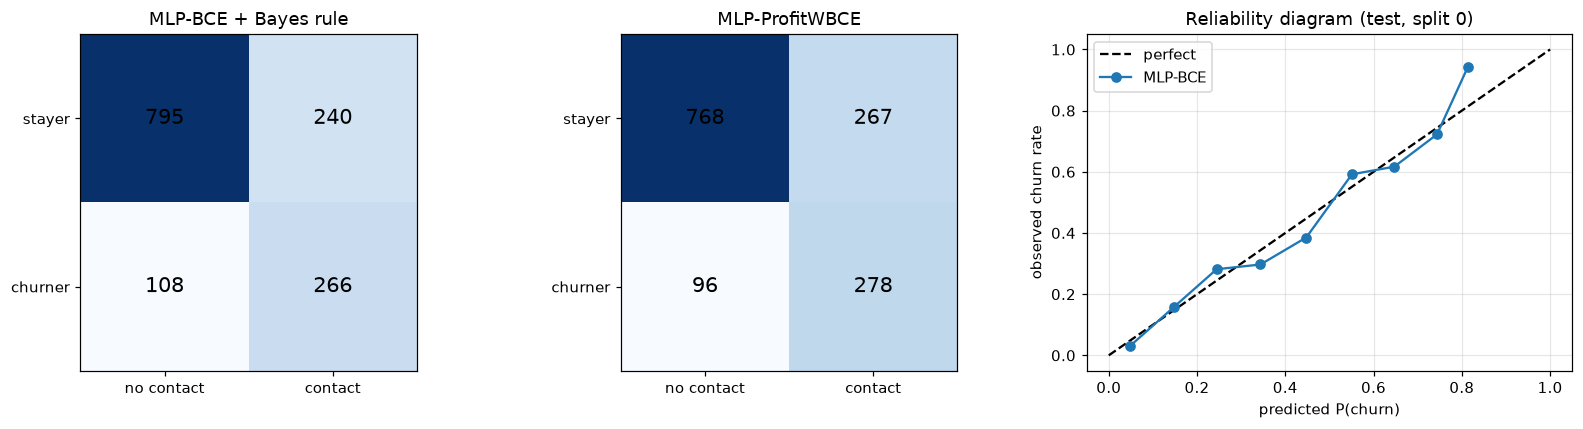

In [12]:
S = store; yte, svte = S["yte"], S["svte"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, mode, z in [(ax[0], "MLP-BCE + Bayes rule", S["zte_b"]), (ax[1], "MLP-ProfitWBCE", S["zte_w"])]:
    contact = decision_bayes(z, svte) if "Bayes" in mode else decision_weighted(z, svte)
    cm = confusion_matrix(yte, contact); a_.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a_.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="k")
    a_.set_xticks([0, 1], ["no contact", "contact"]); a_.set_yticks([0, 1], ["stayer", "churner"]); a_.set_title(mode); a_.grid(False)
    print(mode, "| recall(churners)=%.2f precision=%.2f" % (cm[1,1]/cm[1].sum(), cm[1,1]/max(cm[:,1].sum(),1)))
pc = sigmoid(S["zte_b"]); bins = np.linspace(0, 1, 11); mid, obs, cnt = [], [], []
for i in range(10):
    m = (pc >= bins[i]) & (pc <= bins[i+1]) if i == 9 else (pc >= bins[i]) & (pc < bins[i+1])
    if m.sum() >= 5: mid.append(pc[m].mean()); obs.append(yte[m].mean()); cnt.append(m.sum())
ax[2].plot([0, 1], [0, 1], "k--", label="perfect"); ax[2].plot(mid, obs, "o-", label="MLP-BCE"); ax[2].set_xlabel("predicted P(churn)"); ax[2].set_ylabel("observed churn rate"); ax[2].set_title("Reliability diagram (test, split 0)"); ax[2].legend()
plt.tight_layout(); plt.savefig("figs/fig_confusion_calibration.png"); plt.show()

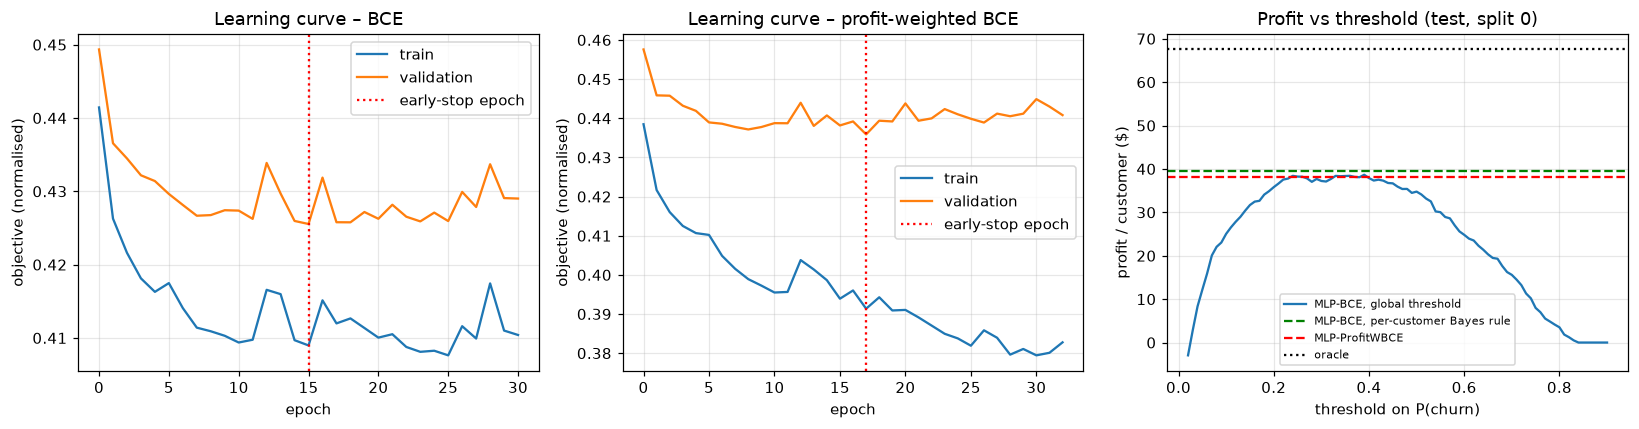

In [13]:
# learning curves of the two selected networks (split 0)  +  profit as a function of the contact threshold
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, key, nm in [(ax[0], "nb", "BCE"), (ax[1], "nw", "profit-weighted BCE")]:
    h = S[key].hist; a_.plot(h["train"], label="train"); a_.plot(h["val"], label="validation"); a_.axvline(S[key].best_ep, color="r", ls=":", label="early-stop epoch")
    a_.set_title(f"Learning curve – {nm}"); a_.set_xlabel("epoch"); a_.set_ylabel("objective (normalised)"); a_.legend()
grid = np.linspace(0.02, 0.9, 89); pr = sigmoid(S["zte_b"])
ax[2].plot(grid, [profit_per_customer((pr > t).astype(float), yte, svte) for t in grid], label="MLP-BCE, global threshold")
ax[2].axhline(profit_per_customer(decision_bayes(S["zte_b"], svte), yte, svte), color="g", ls="--", label="MLP-BCE, per-customer Bayes rule")
ax[2].axhline(profit_per_customer(decision_weighted(S["zte_w"], svte), yte, svte), color="r", ls="--", label="MLP-ProfitWBCE")
ax[2].axhline(oracle_profit(yte, svte), color="k", ls=":", label="oracle"); ax[2].set_xlabel("threshold on P(churn)"); ax[2].set_ylabel("profit / customer ($)"); ax[2].legend(fontsize=7); ax[2].set_title("Profit vs threshold (test, split 0)")
plt.tight_layout(); plt.savefig("figs/fig_learning_profit.png"); plt.show()

In [14]:
# where does the profit come from?  value-share of recoverable churn value captured, by MonthlyCharges quartile (all test splits pooled would leak nothing; here split 0)
q = pd.qcut(svte, 4, labels=["Q1 low $","Q2","Q3","Q4 high $"]); rows = []
for nm, c in [("MLP-BCE+Bayes", decision_bayes(S["zte_b"], svte)), ("MLP-ProfitWBCE", decision_weighted(S["zte_w"], svte))]:
    for g in q.categories:
        m = np.asarray(q == g); rows.append(dict(method=nm, quartile=g, contact_rate=c[m].mean(), profit=profit_per_customer(c[m], yte[m], svte[m]), oracle=oracle_profit(yte[m], svte[m])))
vq = pd.DataFrame(rows); print(vq.pivot(index="quartile", columns="method", values=["contact_rate", "profit"]).round(3)); print("oracle by quartile:", vq[vq.method=="MLP-BCE+Bayes"].oracle.round(2).values)

           contact_rate                       profit               
method    MLP-BCE+Bayes MLP-ProfitWBCE MLP-BCE+Bayes MLP-ProfitWBCE
quartile                                                           
Q1 low $          0.003          0.020         0.189         -0.493
Q2                0.241          0.298        12.107         13.200
Q3                0.608          0.591        70.920         69.198
Q4 high $         0.585          0.639        75.053         71.052
oracle by quartile: [  1.1   44.4  104.83 119.97]


## 10. Loss vs. task objective – measuring the mismatch
(a) Does a lower log-loss imply a higher profit? Per-split scatter of $\Delta$log-loss vs $\Delta$profit between LR / HistGB / MLP. (b) An explicit edge case: two customers for which cross-entropy and the objective disagree. (c) Calibration cost of the value-weighted loss.

mean logloss:
 {'LR (BCE)+Bayes': 0.4178, 'HistGB+Bayes': 0.4144, 'MLP-BCE+Bayes': 0.4198}
mean profit:
 {'LR (BCE)+Bayes': 39.658, 'HistGB+Bayes': 40.244, 'MLP-BCE+Bayes': 39.458}
mean AUC:
 {'LR (BCE)+Bayes': 0.8449, 'HistGB+Bayes': 0.847, 'MLP-BCE+Bayes': 0.843}
                rank_by_logloss  rank_by_AUC  rank_by_profit
LR (BCE)+Bayes              2.0          2.0             2.0
HistGB+Bayes                1.0          1.0             1.0
MLP-BCE+Bayes               3.0          3.0             3.0
best-logloss model != best-profit model in 5/10 splits


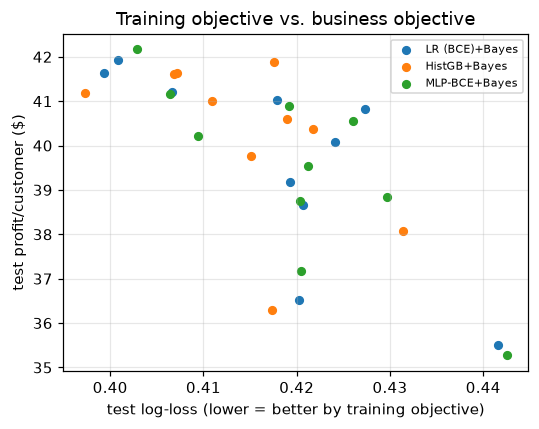

In [15]:
names = ["LR (BCE)+Bayes", "HistGB+Bayes", "MLP-BCE+Bayes"]
ll = pd.DataFrame({n: [r["logloss"] for r in res[n]] for n in names}); pf = pd.DataFrame({n: P[n] for n in names}); au = pd.DataFrame({n: [r["auc"] for r in res[n]] for n in names})
print("mean logloss:\n", ll.mean().round(4).to_dict()); print("mean profit:\n", pf.mean().round(3).to_dict()); print("mean AUC:\n", au.mean().round(4).to_dict())
rk = pd.DataFrame({"rank_by_logloss": ll.mean().rank(), "rank_by_AUC": au.mean().rank(ascending=False), "rank_by_profit": pf.mean().rank(ascending=False)}); print(rk)
# split-level disagreement: how often does the model with the best log-loss NOT have the best profit?
dis = sum(ll.iloc[i].idxmin() != pf.iloc[i].idxmax() for i in range(N_SPLITS)); print(f"best-logloss model != best-profit model in {dis}/{N_SPLITS} splits")
fig, ax = plt.subplots(figsize=(5, 4))
for n in names: ax.scatter(ll[n], pf[n], label=n, s=25)
ax.set_xlabel("test log-loss (lower = better by training objective)"); ax.set_ylabel("test profit/customer ($)"); ax.legend(fontsize=7); ax.set_title("Training objective vs. business objective"); plt.tight_layout(); plt.savefig("figs/fig_logloss_vs_profit.png"); plt.show()

In [16]:
# (b) concrete edge case with the trained MLP-BCE (split 0): same predicted risk, opposite optimal action
pc = sigmoid(S["zte_b"]); dfte = df.iloc[S["te"]].reset_index(drop=True)
cand = pd.DataFrame(dict(MonthlyCharges=dfte.MonthlyCharges, Contract=dfte.Contract, p_churn=pc, sV=svte, threshold=C_OFFER/np.maximum(svte,1e-9), churned=yte))
a_ = cand[(cand.p_churn.between(0.30, 0.36)) & (cand.MonthlyCharges > 95)].head(1); b_ = cand[(cand.p_churn.between(0.30, 0.36)) & (cand.MonthlyCharges.between(30, 45))].head(1)
print(pd.concat([a_, b_]).round(3).to_string()); print("-> equal ~0.33 churn risk; cross-entropy treats both errors equally, but contacting the high-bill customer is +EV and the low-bill one is -EV.")
# (c) calibration cost of the weighted loss: recover P(churn) from the weighted posterior q (valid where a_i>0) and compare ECE
a_te, b_te = class_weights(dfte, "wbce"); q = sigmoid(S["zte_w"]); m = a_te > 0
p_rec = b_te[m]*q[m] / (a_te[m]*(1-q[m]) + b_te[m]*q[m]); print(f"ECE on customers with a_i>0 -> BCE model: {ece_score(pc[m], yte[m]):.3f} | WBCE raw q: {ece_score(q[m], yte[m]):.3f} | WBCE recovered p: {ece_score(np.clip(p_rec,0,1), yte[m]):.3f}")

     MonthlyCharges        Contract  p_churn      sV  threshold  churned
184          104.50  Month-to-month    0.320  501.60      0.199      0.0
364           30.85  Month-to-month    0.322  148.08      0.675      0.0
-> equal ~0.33 churn risk; cross-entropy treats both errors equally, but contacting the high-bill customer is +EV and the low-bill one is -EV.
ECE on customers with a_i>0 -> BCE model: 0.026 | WBCE raw q: 0.161 | WBCE recovered p: 0.046


## 11. Sensitivity to the business assumptions ($c$ and $s$ are not observed in the data)
For each cost / success-rate pair we retrain both losses on 5 splits (width 64, $\lambda=10^{-2}$) and report the mean profit difference (value-weighted − BCE+Bayes) and the contact-all profit. *Weighted model re-derived for every $(c,s)$.*

In [17]:
def run_cs(c, s, n=5, h=64, l2=1e-2):
    out = []
    for k in range(n):
        tr, va, te = make_split(1000 + k); pp = Preprocessor().fit(df.iloc[tr]); Xtr, Xva, Xte = (pp.transform(df.iloc[i]) for i in (tr, va, te))
        ytr, yva, yte = (df.y.values[i].astype(float) for i in (tr, va, te)); svte = sV_of(df.iloc[te], s)
        wbce = [class_weights(df.iloc[i], "wbce", c, s) for i in (tr, va)]; bce = [class_weights(df.iloc[i], "bce") for i in (tr, va)]
        nb = train_mlp(Xtr, ytr, *bce[0], Xva, yva, *bce[1], h, l2, k); nw = train_mlp(Xtr, ytr, *wbce[0], Xva, yva, *wbce[1], h, l2, k)
        pb = profit_per_customer(decision_bayes(nb.forward(Xte), svte, c), yte, svte, c); pw = profit_per_customer(decision_weighted(nw.forward(Xte), svte, c), yte, svte, c)
        out.append((pb, pw, profit_per_customer(np.ones(len(yte)), yte, svte, c), oracle_profit(yte, svte, c)))
    o = np.array(out); return o.mean(0), (o[:, 1] - o[:, 0])
sens = []; cs_grid = [(c, s) for c in (40, 100, 160) for s in (0.2, 0.4, 0.6)] if not FAST else [(100, .4)]
for c, s in cs_grid:
    (pb, pw, pall, por), d = run_cs(c, s); sens.append(dict(c=c, s=s, BCE_Bayes=pb, WBCE=pw, diff=pw-pb, wins=f"{(d>0).sum()}/{len(d)}", contact_all=pall, oracle=por))
sens = pd.DataFrame(sens).round(3); print(sens.to_string(index=False))

  c   s  BCE_Bayes    WBCE   diff wins  contact_all  oracle
 40 0.2     24.144  24.356  0.212  4/5        7.632  37.015
 40 0.4     67.315  67.585  0.270  4/5       55.264  84.647
 40 0.6    113.219 113.203 -0.017  2/5      102.896 132.279
100 0.2      7.213   7.059 -0.155  2/5      -52.368  22.175
100 0.4     40.279  39.884 -0.396  1/5       -4.736  68.777
100 0.6     81.484  81.887  0.403  4/5       42.896 116.352
160 0.2      0.535   0.515 -0.019  2/5     -112.368   9.696
160 0.4     22.394  22.542  0.147  3/5      -64.736  53.934
160 0.6     57.151  56.696 -0.455  2/5      -17.104 100.647


## 12. Generalisation-gap study (hypothesis-space capacity vs. regularisation)
Train the BCE network with width $h\in\{4,16,64,256\}$ and $\lambda\in\{10^{-3},10^{-2}\}$ (3 seeds each, early stopping disabled for a fixed 60 epochs so that capacity — not stopping — drives the gap). We record the train–test log-loss gap and the product of layer Frobenius norms $\prod_\ell\lVert W_\ell\rVert_F$, the quantity that enters norm-based Rademacher bounds $\mathcal R_N\lesssim \frac{B\prod_\ell\lVert W_\ell\rVert_F}{\sqrt N}$ for ReLU networks.

            params   train    test     gap  gap_sd     wnorm
h   l2                                                      
4   0.0001     213  0.4216  0.4119 -0.0096  0.0015   12.1879
    0.0100     213  0.4253  0.4129 -0.0124  0.0014    3.1708
16  0.0001    1041  0.4053  0.4074  0.0021  0.0056   41.2144
    0.0100    1041  0.4217  0.4087 -0.0130  0.0004    2.7654
64  0.0001    7233  0.4006  0.4083  0.0077  0.0069  170.5410
    0.0100    7233  0.4200  0.4084 -0.0116  0.0004    2.8444
256 0.0001   78081  0.4006  0.4063  0.0057  0.0087  646.1048
    0.0100   78081  0.4169  0.4069 -0.0100  0.0017  122.8655


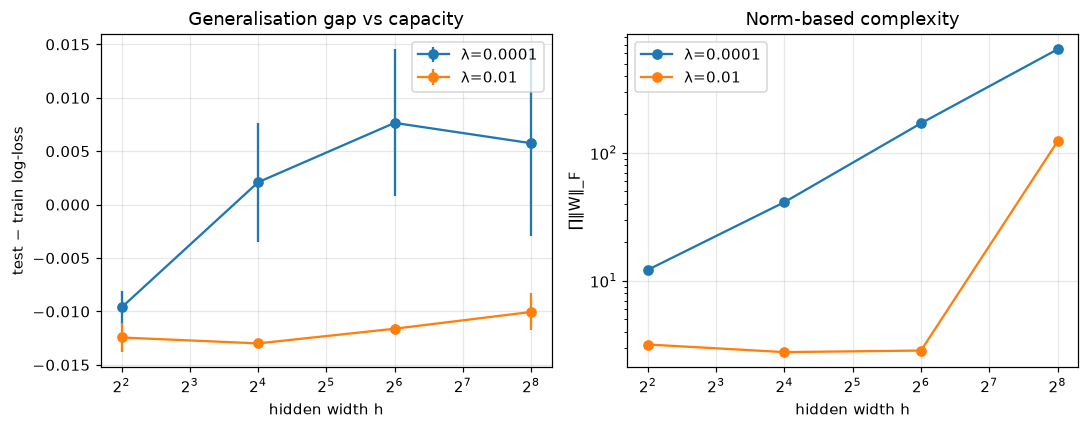

In [18]:
gap_rows = []
tr, va, te = make_split(7); pp = Preprocessor().fit(df.iloc[tr]); Xtr, Xva, Xte = (pp.transform(df.iloc[i]) for i in (tr, va, te)); ytr, yva, yte = (df.y.values[i].astype(float) for i in (tr, va, te))
one = lambda n: (np.ones(n), np.ones(n))
for h in (4, 16, 64, 256):
    for l2 in (1e-4, 1e-2):
        for sd in range(3):
            net = train_mlp(Xtr, ytr, *one(len(ytr)), Xva, yva, *one(len(yva)), h, l2, seed=sd, epochs=60, patience=10**6)
            ltr = objective_value(net.forward(Xtr), ytr, *one(len(ytr)), 1.0); lte = objective_value(net.forward(Xte), yte, *one(len(yte)), 1.0)
            gap_rows.append(dict(h=h, l2=l2, seed=sd, train=ltr, test=lte, gap=lte-ltr, wnorm=float(np.prod([np.linalg.norm(W) for W in net.W])), params=sum(p.size for p in net.params())))
gp = pd.DataFrame(gap_rows); gs = gp.groupby(["h", "l2"]).agg(params=("params", "first"), train=("train", "mean"), test=("test", "mean"), gap=("gap", "mean"), gap_sd=("gap", "std"), wnorm=("wnorm", "mean")).round(4); print(gs)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for l2, g in gp.groupby("l2"):
    a = g.groupby("h").gap.agg(["mean", "std"]); ax[0].errorbar(a.index, a["mean"], a["std"], marker="o", label=f"λ={l2:g}")
    b = g.groupby("h").wnorm.mean(); ax[1].plot(b.index, b.values, marker="o", label=f"λ={l2:g}")
ax[0].set_xscale("log", base=2); ax[0].set_xlabel("hidden width h"); ax[0].set_ylabel("test − train log-loss"); ax[0].legend(); ax[0].set_title("Generalisation gap vs capacity")
ax[1].set_xscale("log", base=2); ax[1].set_yscale("log"); ax[1].set_xlabel("hidden width h"); ax[1].set_ylabel("∏‖W‖_F"); ax[1].legend(); ax[1].set_title("Norm-based complexity")
plt.tight_layout(); plt.savefig("figs/fig_gap.png"); plt.show()

## 13. Export key numbers (used verbatim in the written report)

In [19]:
out = dict(n=len(df), churn_rate=float(df.y.mean()), d=int(Xtr.shape[1]), N_SPLITS=N_SPLITS, H=H, s=S_SUCCESS, c=C_OFFER,
           table=tab.reset_index().to_dict("records"), paired=pt.to_dict("records"), sens=sens.to_dict("records"), gap=gs.reset_index().to_dict("records"),
           extras=extras, dis=int(dis), rank=rk.reset_index().to_dict("records"),
           contact_all=float(np.mean([r["profit"] for r in res["Contact-all"]])), oracle=float(np.mean([r["profit"] for r in res["Oracle"]])))
json.dump(out, open("results.json", "w"), indent=1, default=float); print("saved results.json and figs/*.png")

saved results.json and figs/*.png
